Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving Raw_Sales_Dataset.csv to Raw_Sales_Dataset.csv


analysis

In [ ]:
df = pd.read_csv("Raw_Sales_Dataset.csv")
df.head()
df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order Date     9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   State          9994 non-null   object 
 3   Category       9994 non-null   object 
 4   Sub-Category   9994 non-null   object 
 5   Product Name   9994 non-null   object 
 6   Sales          9994 non-null   float64
 7   Quantity       9994 non-null   int64  
 8   Profit         9994 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 702.8+ KB


,Sales,Quantity,Profit
count,9994.000000,9994.000000,9994.000000
mean,229.858022,3.789574,28.656973
std,623.245131,2.225110,234.260203
min,0.440000,1.000000,-6599.980000
25%,17.280000,2.000000,1.730000
50%,54.490000,3.000000,8.665000
75%,209.940000,5.000000,29.360000
max,22638.480000,14.000000,8399.980000


Clean

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

df = df.drop_duplicates()

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

## Sales by Category

/tmp/ipykernel_3760/3616857476.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Sales', data=sales_by_category, palette='viridis')


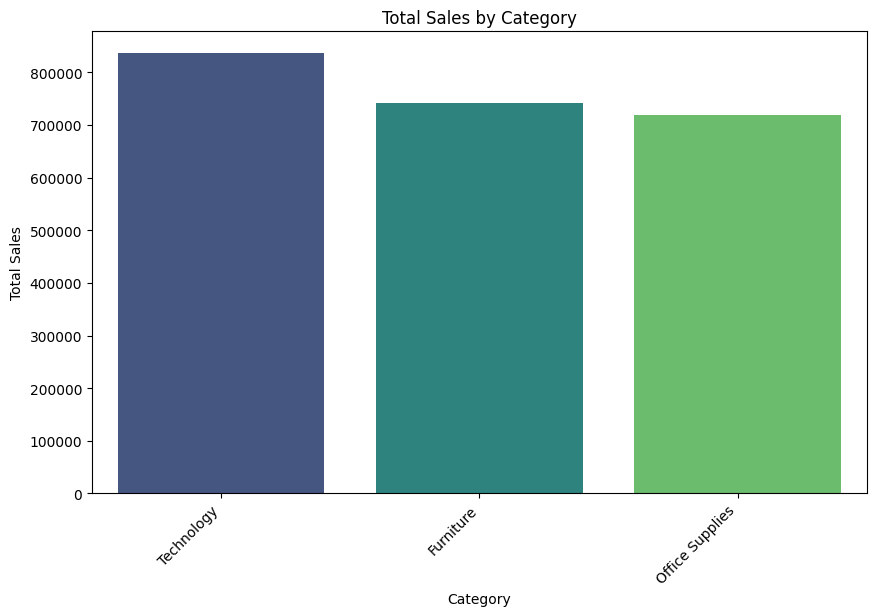

In [ ]:
sales_by_category = df.groupby('Category')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Category', y='Sales', data=sales_by_category, palette='viridis')
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.show()

## Sales by Sub-Category

/tmp/ipykernel_3760/1966311704.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sub-Category', y='Sales', data=sales_by_subcategory, palette='magma')


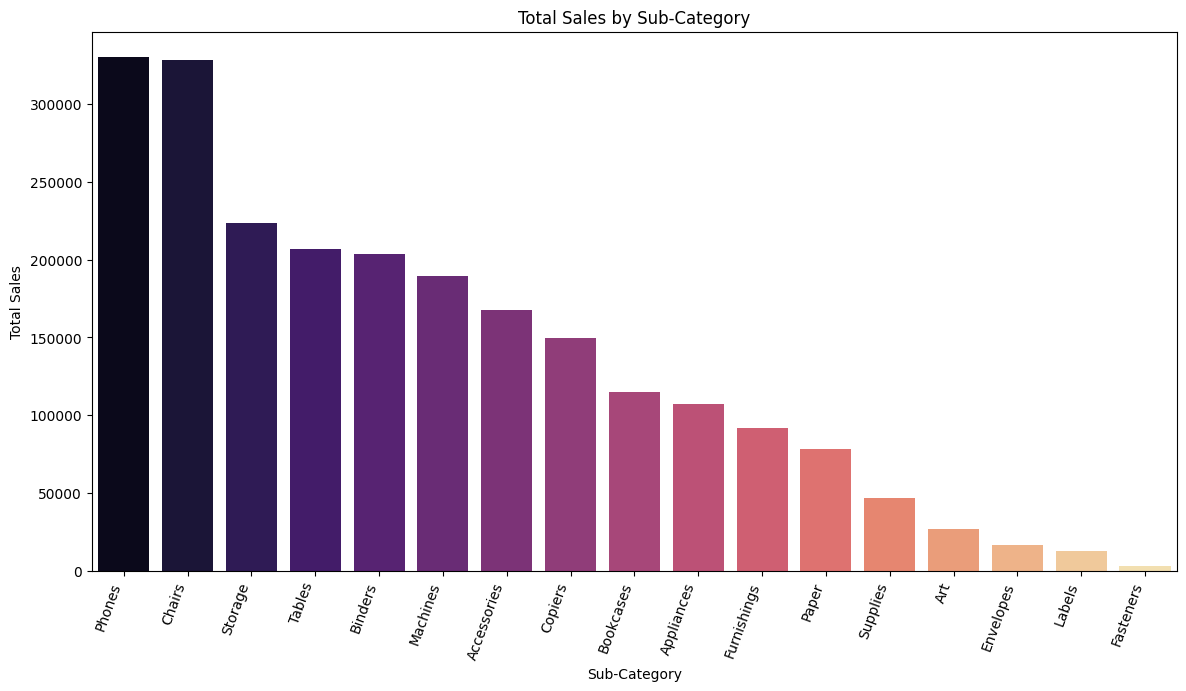

In [ ]:
sales_by_subcategory = df.groupby('Sub-Category')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)

plt.figure(figsize=(14, 7))
sns.barplot(x='Sub-Category', y='Sales', data=sales_by_subcategory, palette='magma')
plt.title('Total Sales by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=70, ha='right')
plt.show()

## Profit by Category

/tmp/ipykernel_3760/622335305.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Profit', data=profit_by_category, palette='cividis')


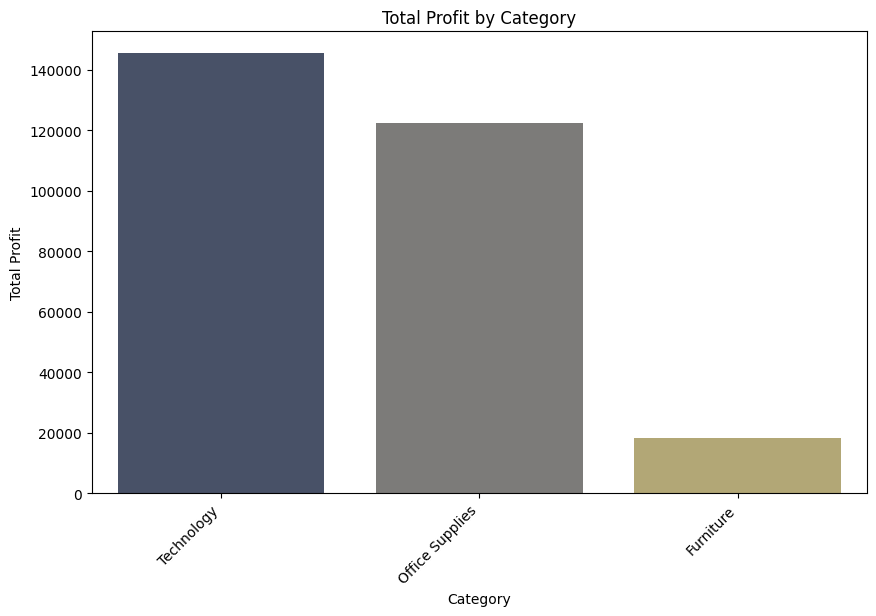

In [ ]:
profit_by_category = df.groupby('Category')['Profit'].sum().reset_index().sort_values(by='Profit', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Category', y='Profit', data=profit_by_category, palette='cividis')
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=45, ha='right')
plt.show()

## Profit by Sub-Category

/tmp/ipykernel_3760/2225727383.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sub-Category', y='Profit', data=profit_by_subcategory, palette='plasma')


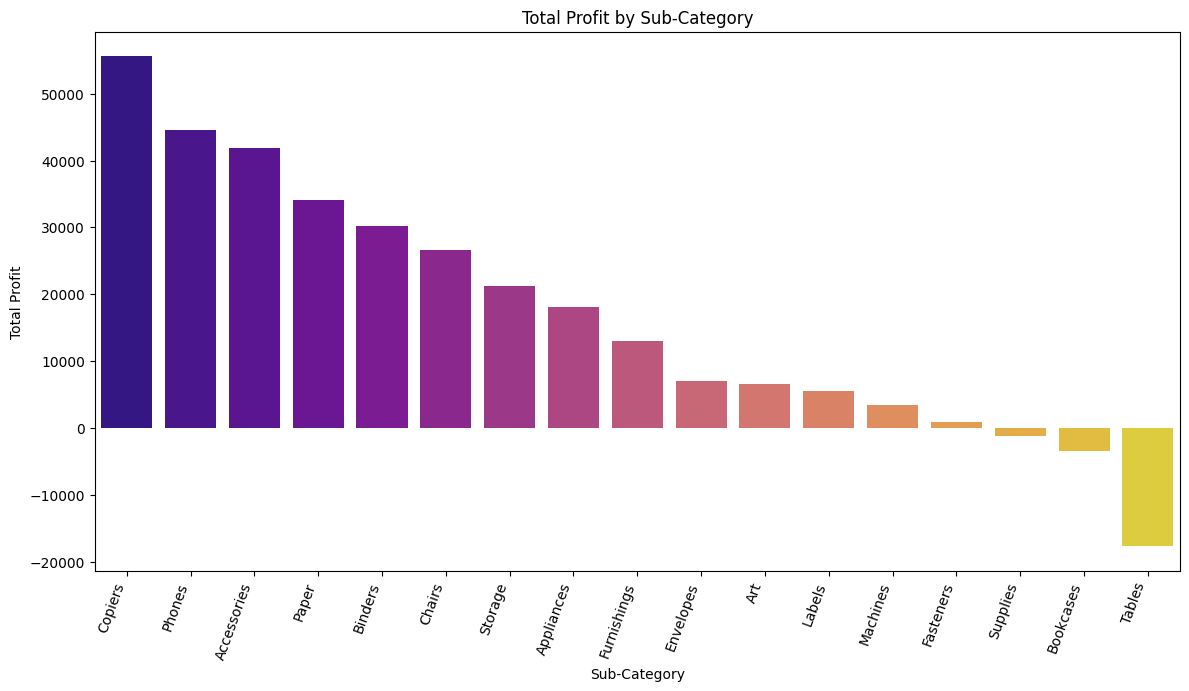

In [ ]:
profit_by_subcategory = df.groupby('Sub-Category')['Profit'].sum().reset_index().sort_values(by='Profit', ascending=False)

plt.figure(figsize=(14, 7))
sns.barplot(x='Sub-Category', y='Profit', data=profit_by_subcategory, palette='plasma')
plt.title('Total Profit by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=70, ha='right')
plt.show()

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

df = df.drop_duplicates()

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

In [ ]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.month_name()

df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

Total Sales



In [ ]:
df["Sales"].sum()

np.float64(2296919.7)

Total Profit

In [ ]:
df["Profit"].sum()

np.float64(286409.85000000003)

Sales by Category

In [ ]:
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

,Sales
Category,
Technology,836154.10
Furniture,741718.61
Office Supplies,719046.99


Monthly Sales

In [ ]:
monthly_sales = df.groupby("Month_Name")["Sales"].sum()

Top 10 Products

In [ ]:
top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
top_products

,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.83
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48
HON 5400 Series Task Chairs for Big and Tall,21870.57
GBC DocuBind TL300 Electric Binding System,19823.48
GBC Ibimaster 500 Manual ProClick Binding System,19024.50
Hewlett Packard LaserJet 3310 Copier,18839.68
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90
GBC DocuBind P400 Electric Binding System,17965.07


In [ ]:
df.to_csv("Cleaned_Sales_Dataset.csv", index=False)

In [ ]:
import os

os.listdir()

['.config',
 'Cleaned_Sales_Dataset.csv',
 'Raw_Sales_Dataset.csv',
 'Sales_Dashboard.xlsx',
 'sample_data']

In [ ]:
from google.colab import files

files.download("Cleaned_Sales_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("Raw_Sales_Dataset.csv")

df.head()

,Order Date,Customer Name,State,Category,Sub-Category,Product Name,Sales,Quantity,Profit
0,03-01-2014,Darren Powers,Texas,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,5.55
1,04-01-2014,Phillina Ober,Illinois,Office Supplies,Labels,Avery 508,11.78,3,4.27
2,04-01-2014,Phillina Ober,Illinois,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,-64.77
3,04-01-2014,Phillina Ober,Illinois,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,-5.49
4,05-01-2014,Mick Brown,Pennsylvania,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,4.88


In [ ]:
df.shape

(9994, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order Date     9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   State          9994 non-null   object 
 3   Category       9994 non-null   object 
 4   Sub-Category   9994 non-null   object 
 5   Product Name   9994 non-null   object 
 6   Sales          9994 non-null   float64
 7   Quantity       9994 non-null   int64  
 8   Profit         9994 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 702.8+ KB


In [ ]:
df.isnull().sum()

,0
Order Date,0
Customer Name,0
State,0
Category,0
Sub-Category,0
Product Name,0
Sales,0
Quantity,0
Profit,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df.describe()

,Sales,Quantity,Profit
count,9994.000000,9994.000000,9994.000000
mean,229.858022,3.789574,28.656973
std,623.245131,2.225110,234.260203
min,0.440000,1.000000,-6599.980000
25%,17.280000,2.000000,1.730000
50%,54.490000,3.000000,8.665000
75%,209.940000,5.000000,29.360000
max,22638.480000,14.000000,8399.980000


In [ ]:
df.to_csv("Cleaned_Sales_Dataset.csv", index=False)

In [ ]:
import os

os.listdir()

['.config',
 'Cleaned_Sales_Dataset.csv',
 'Raw_Sales_Dataset.csv',
 'Sales_Dashboard.xlsx',
 'sample_data']

In [ ]:
from google.colab import files

files.download("Cleaned_Sales_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.columns.tolist()

['Order Date',
 'Customer Name',
 'State',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Profit']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order Date     9994 non-null   object 
 1   Customer Name  9994 non-null   object 
 2   State          9994 non-null   object 
 3   Category       9994 non-null   object 
 4   Sub-Category   9994 non-null   object 
 5   Product Name   9994 non-null   object 
 6   Sales          9994 non-null   float64
 7   Quantity       9994 non-null   int64  
 8   Profit         9994 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 702.8+ KB


In [ ]:
df = pd.read_csv("Raw_Sales_Dataset.csv")

In [ ]:
print(df.columns.tolist())

['Order Date', 'Customer Name', 'State', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Profit']


In [ ]:
df.head()

,Order Date,Customer Name,State,Category,Sub-Category,Product Name,Sales,Quantity,Profit
0,03-01-2014,Darren Powers,Texas,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,5.55
1,04-01-2014,Phillina Ober,Illinois,Office Supplies,Labels,Avery 508,11.78,3,4.27
2,04-01-2014,Phillina Ober,Illinois,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,-64.77
3,04-01-2014,Phillina Ober,Illinois,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,-5.49
4,05-01-2014,Mick Brown,Pennsylvania,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,4.88


In [ ]:
df.shape

(9994, 9)

In [ ]:
# Make a copy
mysql_df = df.copy()

# Convert Order Date to proper date
mysql_df["Order Date"] = pd.to_datetime(
    mysql_df["Order Date"],
    dayfirst=True
)

# Rename columns for MySQL
mysql_df.columns = [
    "Order_Date",
    "Customer_Name",
    "State",
    "Category",
    "Sub_Category",
    "Product_Name",
    "Sales",
    "Quantity",
    "Profit"
]

# Save
mysql_df.to_csv(
    "Sales_Data_MySQL.csv",
    index=False
)

print(mysql_df.columns.tolist())
print(mysql_df.shape)

['Order_Date', 'Customer_Name', 'State', 'Category', 'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Profit']
(9994, 9)


In [ ]:
from google.colab import files

files.download("Cleaned_Sales_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(9993, 9)

In [ ]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

In [ ]:
df.dtypes

,0
Order Date,datetime64[ns]
Customer Name,object
State,object
Category,object
Sub-Category,object
Product Name,object
Sales,float64
Quantity,int64
Profit,float64


In [ ]:
# Remove duplicate
df = df.drop_duplicates()

# Convert date
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

# Check
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(9993, 9)
Order Date       datetime64[ns]
Customer Name            object
State                    object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Profit                  float64
dtype: object
Order Date       0
Customer Name    0
State            0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Profit           0
dtype: int64


In [ ]:
df.to_csv("Cleaned_Sales_Data.csv", index=False)